In [54]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE

In [4]:
milk = pd.read_csv("F:\MACHINE LEARNING\SOMETHING\Datasets\milk.csv", index_col = 0)
scaler = StandardScaler().set_output(transform = 'pandas')
scl_milk = scaler.fit_transform(milk)

In [9]:
prcomp = PCA().set_output(transform = 'pandas')
pca_data = prcomp.fit_transform(scl_milk)

In [10]:
print(pca_data.shape)
print(milk.shape)

(25, 5)
(25, 5)


In [11]:
pca_data

,pca0,pca1,pca2,pca3,pca4
Animal,,,,,
HORSE,2.435175,-0.231478,0.330150,0.307664,0.048184
ORANGUTAN,2.258736,-0.693148,0.029035,-0.081057,-0.000532
MONKEY,2.335861,-0.663328,0.101257,0.247997,0.010109
DONKEY,2.318677,-0.273815,0.109881,-0.092873,-0.006769
HIPPO,2.060294,-1.019199,-0.762436,-0.510091,0.029382
CAMEL,1.301536,0.137303,-0.198742,-0.282160,-0.014668
BISON,1.282742,0.622667,0.253785,0.065148,-0.044486
BUFFALO,0.505068,0.088235,0.008383,0.133774,0.083806
GUINEA PIG,-0.255502,0.287373,-0.881857,-0.013100,-0.016484


In [12]:
pca_data.var()

pca0    4.040412
pca1    0.924372
pca2    0.134291
pca3    0.102689
pca4    0.006570
dtype: float64

In [13]:
sigma = scl_milk.cov()
values, vectore = np.linalg.eig(sigma)
print('Eigen values: ', values)

Eigen values:  [4.0404117  0.92437238 0.00656977 0.13429088 0.1026886 ]


In [17]:
prcomp.explained_variance_

array([4.0404117 , 0.92437238, 0.13429088, 0.1026886 , 0.00656977])

In [14]:
total_variation = pca_data.var().sum()
total_variation

np.float64(5.208333333333338)

In [15]:
pca_data.var()/total_variation

pca0    0.775759
pca1    0.177479
pca2    0.025784
pca3    0.019716
pca4    0.001261
dtype: float64

In [16]:
prcomp.explained_variance_ratio_

array([0.77575905, 0.1774795 , 0.02578385, 0.01971621, 0.0012614 ])

In [18]:
prcomp.explained_variance_ratio_*100  #percentage variation explained by each PCi

array([77.57590469, 17.74794969,  2.57838496,  1.97162103,  0.12613963])

In [19]:
np.cumsum(prcomp.explained_variance_ratio_*100)

array([ 77.57590469,  95.32385438,  97.90223934,  99.87386037,
       100.        ])

for example, PC1 and PC2 together retains 95% story of data.

In [21]:
pca_data[['pca0', 'pca1']]

,pca0,pca1
Animal,,
HORSE,2.435175,-0.231478
ORANGUTAN,2.258736,-0.693148
MONKEY,2.335861,-0.663328
DONKEY,2.318677,-0.273815
HIPPO,2.060294,-1.019199
CAMEL,1.301536,0.137303
BISON,1.282742,0.622667
BUFFALO,0.505068,0.088235
GUINEA PIG,-0.255502,0.287373


In [55]:
wisc = pd.read_csv("F:\MACHINE LEARNING\SOMETHING\Cases\Wisconsin\BreastCancer.csv", index_col = 0)
X, y = wisc.drop('Class', axis = 1), wisc.Class

In [23]:
scaler = StandardScaler().set_output(transform = 'pandas')
scl = scaler.fit_transform(X)

In [24]:
prcomp = PCA().set_output(transform = 'pandas')
pca_data = prcomp.fit_transform(scl)

In [29]:
print('Eigen values: ',prcomp.explained_variance_)
print(prcomp.explained_variance_ratio_)
print('Percentage: ',prcomp.explained_variance_ratio_*100)

Eigen values:  [5.89933341 0.77747488 0.53962409 0.46291365 0.38027213 0.30572325
 0.29602105 0.26271236 0.08881915]
[0.65454375 0.08626251 0.05987245 0.05136127 0.04219201 0.03392065
 0.03284417 0.0291485  0.00985468]
Percentage:  [65.45437483  8.62625123  5.98724547  5.13612665  4.21920122  3.39206535
  3.28441735  2.91485025  0.98546764]


In [28]:
np.cumsum(prcomp.explained_variance_ratio_*100)

array([ 65.45437483,  74.08062606,  80.06787153,  85.20399818,
        89.42319941,  92.81526476,  96.09968211,  99.01453236,
       100.        ])

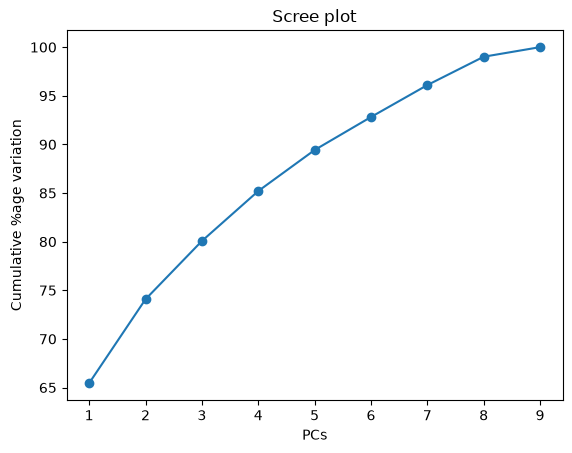

In [32]:
plt.scatter(range(1,10), np.cumsum(prcomp.explained_variance_ratio_*100))
plt.plot(range(1,10), np.cumsum(prcomp.explained_variance_ratio_*100))
plt.title('Scree plot')
plt.xlabel('PCs')
plt.ylabel('Cumulative %age variation')
plt.show()

In [33]:
new_data = pd.concat([pca_data[['pca0', 'pca1']], y], axis=1)
new_data

,pca0,pca1,Class
Code,,,
61634,-0.661561,-0.168216,Benign
63375,2.178759,-0.693348,Malignant
76389,1.404956,-1.364750,Malignant
95719,6.073098,1.994961,Malignant
128059,-1.237518,-0.370332,Benign
...,...,...,...
1369821,6.473443,1.285709,Malignant
1371026,4.097345,-0.215083,Malignant
1371920,-1.351669,-0.095164,Benign


<Axes: xlabel='pca0', ylabel='pca1'>

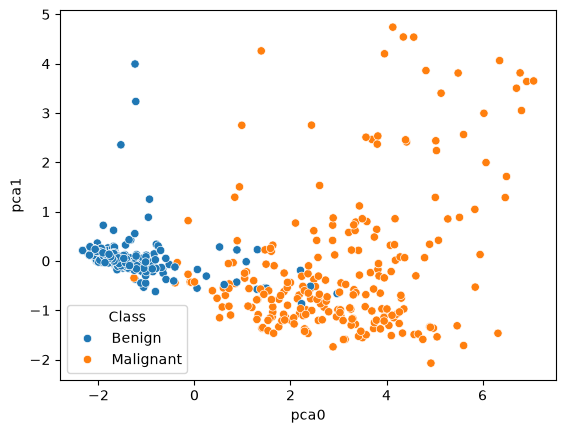

In [36]:
sns.scatterplot(data=new_data, x= 'pca0', y = 'pca1', hue = 'Class')

### SVM

In [43]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from sklearn.pipeline import Pipeline

In [41]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.3, random_state=26, stratify = y)
svm = SVC(kernel='linear')
svm.fit(X_train, y_train)
pred = svm.predict(X_test)
f1_score(y_test, pred, pos_label= 'Malignant')

0.9324324324324325

In [52]:
prcomp = PCA()
pipe = Pipeline([('SCL', scaler), ('PCA', prcomp),('SVM', svm)])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
f1_score(y_test, y_pred, pos_label = 'Malignant')

0.9324324324324325

In [51]:
prcomp = PCA(n_components=5)
pipe = Pipeline([('SCL', scaler), ('PCA', prcomp),('SVM', svm)])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
f1_score(y_test, y_pred, pos_label = 'Malignant')

0.9530201342281879

ModuleNotFoundError: No module named 'pca'